<a href="https://colab.research.google.com/github/SnehaGupta359/first-demo/blob/main/Support_Vector_Machine_and_Naive_Bayes_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("/content/spam_email_dataset.csv")

print(df.head())

print("Dataset Shape:", df.shape)

print(df.info())

   email_id           subject  \
0         0     Weekly Report   
1         1    Project Update   
2         2    🔥WIN BIG NOW!!   
3         3    🔥WIN BIG NOW!!   
4         4  Meeting Reminder   

                                          email_text  num_words  \
0  budget review - Statement our I claim world st...         19   
1  team sync - President series today already. In...         18   
2  win free urgent offer limited limited urgent u...         19   
3  guarantee click now cash offer click now guara...         16   
4  team sync - Significant property hotel not add...         18   

   num_characters  num_exclamation_marks  num_links  has_suspicious_link  \
0             114                      0          2                    0   
1             114                      0          7                    0   
2             126                      0          4                    1   
3             101                      0          7                    1   
4             111 

In [3]:
print(df.isnull().sum())

email_id                   0
subject                    0
email_text                 0
num_words                  0
num_characters             0
num_exclamation_marks      0
num_links                  0
has_suspicious_link        0
num_attachments            0
has_attachment             0
sender_email               0
sender_domain              0
sender_reputation_score    0
email_hour                 0
email_day_of_week          0
is_weekend                 0
num_recipients             0
contains_money_terms       0
contains_urgency_terms     0
label                      0
dtype: int64


In [4]:
df['combined_text'] = (
    df['subject'].fillna('') + " " +
    df['email_text'].fillna('')
)

In [5]:
numeric_features = [
    'num_words',
    'num_characters',
    'num_exclamation_marks',
    'num_links',
    'has_suspicious_link',
    'num_attachments',
    'has_attachment',
    'sender_reputation_score',
    'email_hour',
    'email_day_of_week',
    'is_weekend',
    'num_recipients',
    'contains_money_terms',
    'contains_urgency_terms'
]

X = df[
    ['combined_text', 'sender_domain'] + numeric_features
]

y = df['label']

In [6]:
preprocessor = ColumnTransformer(

    transformers=[

        ('text',

         TfidfVectorizer(
             stop_words='english',
             ngram_range=(1, 2),
             max_features=20000,
             sublinear_tf=True
         ),

         'combined_text'),

        ('domain',

         OneHotEncoder(handle_unknown='ignore'),

         ['sender_domain']),

        ('numeric',

         MinMaxScaler(),

         numeric_features)

    ]
)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42,

    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (8000, 16)
Testing Data: (2000, 16)


In [8]:
svm_model = Pipeline([

    ('preprocessor', preprocessor),

    ('classifier', LinearSVC(random_state=42))

])

# Train SVM
svm_model.fit(X_train, y_train)

# Prediction
svm_pred = svm_model.predict(X_test)

print("SVM Model Training Completed!")

SVM Model Training Completed!


In [9]:
print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred) * 100)

print("SVM Precision:",
      precision_score(y_test, svm_pred))

print("SVM Recall:",
      recall_score(y_test, svm_pred))

print("SVM F1 Score:",
      f1_score(y_test, svm_pred))

SVM Accuracy: 100.0
SVM Precision: 1.0
SVM Recall: 1.0
SVM F1 Score: 1.0


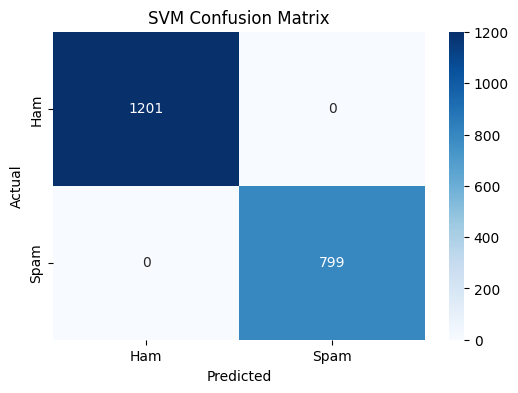

In [10]:
svm_cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("SVM Confusion Matrix")

plt.show()

In [11]:
nb_model = Pipeline([

    ('preprocessor', preprocessor),

    ('classifier', MultinomialNB())

])

# Train Naive Bayes
nb_model.fit(X_train, y_train)

# Prediction
nb_pred = nb_model.predict(X_test)

print("Naive Bayes Training Completed!")

Naive Bayes Training Completed!


In [12]:
print("Naive Bayes Accuracy:",
      accuracy_score(y_test, nb_pred) * 100)

print("Naive Bayes Precision:",
      precision_score(y_test, nb_pred))

print("Naive Bayes Recall:",
      recall_score(y_test, nb_pred))

print("Naive Bayes F1 Score:",
      f1_score(y_test, nb_pred))

Naive Bayes Accuracy: 100.0
Naive Bayes Precision: 1.0
Naive Bayes Recall: 1.0
Naive Bayes F1 Score: 1.0


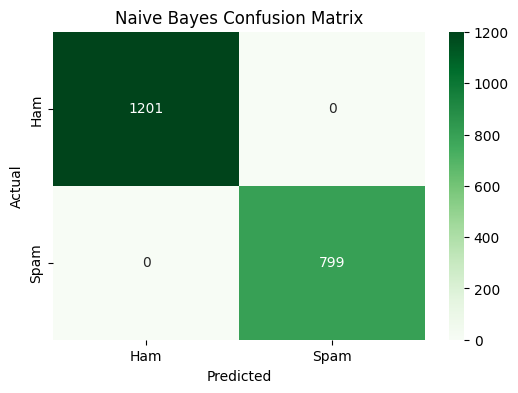

In [13]:
nb_cm = confusion_matrix(y_test, nb_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Naive Bayes Confusion Matrix")

plt.show()

In [15]:
print("SVM Classification Report")

print(
    classification_report(
        y_test,
        svm_pred,
        target_names=['Ham', 'Spam']
    )
)

SVM Classification Report
              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00      1201
        Spam       1.00      1.00      1.00       799

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [16]:
print("Naive Bayes Classification Report")

print(
    classification_report(
        y_test,
        nb_pred,
        target_names=['Ham', 'Spam']
    )
)

Naive Bayes Classification Report
              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00      1201
        Spam       1.00      1.00      1.00       799

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [17]:
results = pd.DataFrame({

    'Algorithm': ['SVM', 'Naive Bayes'],

    'Accuracy': [
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, nb_pred)
    ],

    'Precision': [
        precision_score(y_test, svm_pred),
        precision_score(y_test, nb_pred)
    ],

    'Recall': [
        recall_score(y_test, svm_pred),
        recall_score(y_test, nb_pred)
    ],

    'F1 Score': [
        f1_score(y_test, svm_pred),
        f1_score(y_test, nb_pred)
    ]

})

print(results)

     Algorithm  Accuracy  Precision  Recall  F1 Score
0          SVM       1.0        1.0     1.0       1.0
1  Naive Bayes       1.0        1.0     1.0       1.0


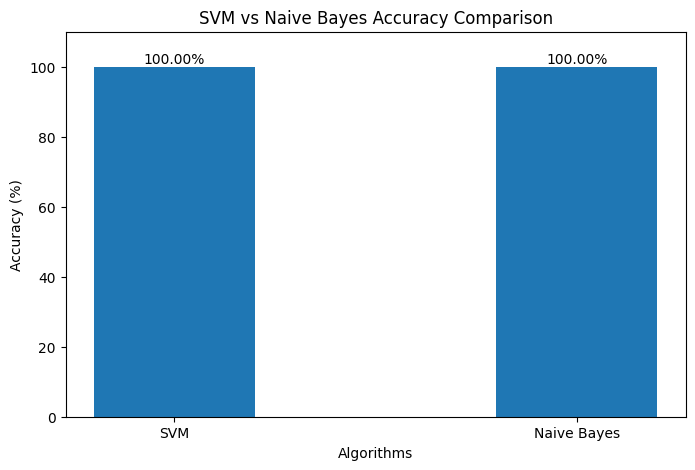

In [18]:
plt.figure(figsize=(8, 5))

algorithms = ['SVM', 'Naive Bayes']

accuracies = [
    accuracy_score(y_test, svm_pred) * 100,
    accuracy_score(y_test, nb_pred) * 100
]

plt.bar(
    algorithms,
    accuracies,
    width=0.4
)

plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")

plt.title("SVM vs Naive Bayes Accuracy Comparison")

plt.ylim(0, 110)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()